# Characterisation: what is the spam?

**COS30015 Assignment 2, Attacker or Malware Analysis, Option 1, report section 3.1.** All 1,742 traced spam messages are characterised by language, topic, purpose and technique, with the figures for the report.

## The idea in plain English

We have 1,742 real spam and phishing emails. Before judging how well a filter handles them, we want to know **what they are**: Which languages? What are they about (fake invoices, pharmacy offers, account warnings...)? What does the sender want? What tricks do they use to hide or to look trustworthy?

The method is deliberately simple and transparent: **keyword rules**. A rule is a pattern of words (a *regular expression*); if a message matches the pattern, it gets that label. Rules are easy to read and to argue with, but they are also crude, so the last section lists their limits.

## Words you will meet

| Word | Meaning |
|---|---|
| **regular expression (regex)** | A pattern for finding text. `a\|b` means "a or b"; `\b` marks a word edge; `\d` is a digit; `?` makes the previous character optional. |
| **topic** | What the message is about (for example "credential phishing"). Chosen by keyword rules. |
| **purpose** | What the sender wants (for example "credential theft"). This is an analyst's mapping from the topic, not something the message says. |
| **technique** | A trick used by the message: urgency wording, hidden text, tracking pixel, look-alike letters, and so on. |
| **hidden text** | Text styled so a person cannot see it (for example tiny or white), often to confuse filters. |
| **tracking pixel** | A 1 x 1 invisible image that tells the sender the message was opened. |
| **homoglyph** | A letter from another alphabet that looks like a Latin letter (Cyrillic "а" for "a"). |
| **punycode** | The plain-ASCII encoding of an internationalised domain name (it starts with `xn--`); sometimes used for look-alike domains. |
| **campaign** | A cluster of near-identical messages from one operation. |

## What this notebook does

| Step | Where | What |
|---|---|---|
| HTML and attachment features | `scripts/extract_traced_features.py` (reads raw mail, so it stays a script run with `python -I`) | counts and flags per message -> `data/processed/traced_features.csv` (no text) |
| Language | section 2 | `langdetect` (fixed seed) on the cleaned text |
| Topic and purpose | sections 3 and 4 | English keyword rules; the purpose is an analyst mapping from the topic |
| Techniques | section 5 | wording rules on the cleaned text plus the HTML features |
| Aggregates and figures | sections 6 to 8 | message share and campaign-weighted share, per corpus |

## Campaign weighting (why every share is reported twice)

Messages from one campaign are near-identical, so a few big campaigns can dominate the message counts. Example: if one pharmacy campaign sends 100 copies and 99 other campaigns send 1 message each, pharmacy is 50% of the *messages* but only 1% of the *campaigns*. Every share is therefore reported twice: as a share of **messages**, and as a share of **campaigns** (each message weighted by 1 / the size of its campaign cluster, so every campaign counts once).

## Safety

This notebook reads only the cleaned text (`traced_all.csv`) and the feature file. **No raw mail, HTML or attachment is opened here.** By default it asserts that everything it computes equals the files saved by the original run (`characterised.csv`, `results/char_*.csv`), so it is safe to run repeatedly.

## 1. Setup and inputs

**What we do:** import the libraries, load the cleaned spam text and the feature file, and check that the two files describe the same 1,742 messages in the same order.

In [1]:
# --- Standard library ---
import os
import re                                  # regular expressions
from pathlib import Path

# --- Third-party libraries ---
import matplotlib.pyplot as plt            # figures
import numpy as np                         # arrays of numbers
import pandas as pd                        # tables
from langdetect import DetectorFactory, detect_langs     # guess the language of a text

# --- Settings ---
PROC, RESULTS, FIGS = Path("../data/processed"), Path("../results"), Path("../figures")
WRITE = os.environ.get("WRITE", "1") == "1"     # rewrite the outputs (they must equal the saved ones, so this changes nothing)
DetectorFactory.seed = 0                        # langdetect is random unless seeded: this makes it repeatable

In [2]:
traced = pd.read_csv(PROC / "traced_all.csv", dtype=str, keep_default_na=False)    # cleaned text of every message
traced["year"] = traced.year.astype(int)
features = pd.read_csv(PROC / "traced_features.csv")                               # HTML / attachment flags (no text)

# Sanity checks: same messages, same order, and the feature file was built from this very text.
assert len(traced) == len(features) == 1742 and (traced.id.values == features.id.values).all()
assert (traced.text.str.len().values == features.text_chars.values).all(), "feature file does not match the cleaned text"
print(traced.corpus.value_counts().to_dict(), "| clusters (campaigns):", traced.cluster.nunique())

{'guenter-2026-10': 877, 'nazario-2025': 444, 'nazario-2024': 376, 'phishing-pot': 45} | clusters (campaigns): 680


## 2 to 5. Rules: language, topic, purpose and techniques

**Language.** `langdetect` guesses the language from the cleaned text. Very short texts (fewer than 40 letters) are reported as "und" (undetermined).

**Topic.** Each message gets the topic with the **most distinct keyword hits** (ties go to the order of the list). The keywords are English only; non-English text with no hit is reported as "non-English (unclassified)", English text with no hit as "other".

*Rule history:* the rules were written first, then refined twice after an NMF look at the messages left in "other" (file-share and mail-notice lures added to credential phishing, health lures to pharma and health, a survey/reward topic added, and the non-English rule). No label was checked by hand, and "other" is reported as it comes out.

**Purpose.** What the sender wants, mapped from the topic. This is an analyst assumption, not something a message states.

**Techniques.** Three kinds of evidence:
* *wording rules* (urgency, credential request, money, brand names),
* *character tricks* (zero-width characters, mixed alphabets, spaced letters, leetspeak, long random strings), and
* the *HTML features* from the feature file (hidden CSS text, HTML-only body, tracking pixel, URL shorteners, punycode, link text different from its target, attachments, image-only body as a proxy for image spam).

QR codes inside images cannot be detected from text.

In [3]:
# ---- Topic rules. Each topic is one regular expression: a list of keywords separated by "|" (meaning "or").
# The primary topic is the one with the most distinct keyword hits; ties go to the order of this list.
TOPICS = {
    "credential phishing": r"password|verify your|verification|log ?in|sign ?in|mailbox|security alert|suspend|deactivat|expire|office ?365|microsoft|outlook|webmail|sharepoint|onedrive|docusign|storage (?:is )?full|account (?:has|will|is)|unusual activity|confirm your|shared (?:a |the |you )?(?:file|document|folder)|view (?:the )?(?:document|file|message)|quarantine|undelivered|pending (?:messages?|emails?)|action required|secure message|email (?:account|address) (?:will|has|is)|incoming messages?|shared item|item (?:was |has been )?shared|online (?:file|document)|access (?:file|item|document)",
    "invoice / payment": r"invoice|payment|receipt|purchase order|remittance|wire transfer|bank transfer|overdue|statement of account|\bpo\b|quotation|\brfq\b",
    "delivery / shipping": r"parcel|shipment|delivery|courier|\bdhl\b|fedex|\bups\b|tracking number|package|customs",
    "pharma / health": r"viagra|cialis|pharmacy|pills?|prescription|weight loss|supplement|medication|erectile|\brx\b|dental|teeth|fungus|prostate|blood (?:sugar|pressure)|diabetes|joint pain|doctor|\bcure|\bsugar\b|memory|\bnails?\b|breakthrough|miracle",
    "crypto / investment": r"bitcoin|crypto|wallet|invest|trading|forex|\bbtc\b|\busdt\b|\btoken\b|stock|returns",
    "advance fee / lottery": r"lottery|winner|prize|inherit|million|beneficiary|next of kin|foreign (?:bank|transfer)|dear friend|fund[s ]|barrister|\busd\b|\bgbp\b",
    "loans / finance": r"\bloan|credit (?:card|score)|mortgage|refinanc|\bdebt|interest rate|insurance",
    "survey / reward": r"survey|reward|gift ?card|complimentary|congratulations|loyalty|exclusive (?:offer|member|access)|you(?:'ve| have) been selected|costco|garmin|walmart",
    "job / romance": r"job offer|hiring|vacanc|work from home|recruit|dating|lonely|single (?:women|ladies)|relationship",
    "adult": r"\bsex|\badult|\bnude|\bxxx|escort",
    "marketing / offers": r"\bsale\b|discount|% off|free (?:shipping|gift|trial)|order now|special offer|\bdeal|\bbuy\b|coupon|limited time",
}

# What the sender wants, by topic (an analyst mapping, stated in the report as an assumption).
PURPOSE = {
    "credential phishing": "credential theft / account takeover", "invoice / payment": "payment fraud (invoice, BEC) or malware lure",
    "delivery / shipping": "credential or card theft via fake delivery notice", "pharma / health": "illegal or counterfeit goods sales",
    "crypto / investment": "investment fraud", "advance fee / lottery": "advance-fee fraud", "loans / finance": "fee fraud or lead generation",
    "job / romance": "fee fraud, mule recruitment or romance scam", "adult": "adult advertising or sextortion",
    "survey / reward": "lead harvesting or card/credential theft via fake reward", "marketing / offers": "advertising / affiliate spam",
    "other": "unclear from text", "non-English (unclassified)": "not classified (keyword rules are English only)",
}
TOPIC_RE = {topic: re.compile(pattern, re.I) for topic, pattern in TOPICS.items()}      # re.I = ignore upper/lower case

In [4]:
# ---- Technique rules on the cleaned text. Each one is a regular expression that looks for a particular trick.
URGENCY = re.compile(r"urgent|immediately|within \d+ ?(?:hours?|hrs|days?)|act now|final (?:notice|warning)|last (?:chance|warning)|expires? (?:today|soon|in)|suspend|deactivat|as soon as possible|\basap\b|limited time|don'?t miss", re.I)
CRED_REQ = re.compile(r"password|log ?in|sign ?in|verify|confirm your|update your (?:account|payment|billing)|enter your", re.I)
MONEY = re.compile(r"[$£€]\s?\d|\b\d[\d,.]* ?(?:usd|gbp|eur)\b|payment|invoice|wire|transfer|bitcoin|btc", re.I)
BRANDS = re.compile(r"microsoft|office ?365|outlook|google|gmail|apple|icloud|amazon|paypal|netflix|dhl|fedex|\bups\b|docusign|dropbox|adobe|linkedin|facebook|instagram|\bbank\b|visa|mastercard|wells fargo|chase|hsbc|coinbase|binance", re.I)

# Character tricks (the odd characters are written as \u escapes so you can see what they are):
BLOB = re.compile(r"(?<![\w\[.])[A-Za-z0-9+/=_-]{24,}(?![\w\]])")        # long random-looking tokens (hash-busting padding, or an undecoded body)
ZEROWIDTH = re.compile("[​‌‍⁠﻿]")               # invisible characters (zero-width space, joiners, word joiner, BOM)
MIXED_SCRIPT = re.compile(r"\b(?=\w*[a-z])(?=\w*[Ѐ-ӿͰ-Ͽ])\w+\b", re.I)   # Latin letters mixed with Cyrillic/Greek inside one word
SPACED = re.compile(r"(?:\b\w[ .\-_]){5,}\w\b")                          # "v i a g r a"  or  "p.a.s.s.w.o.r.d"
LEET = re.compile(r"\b(?:v[i1!]agra|c[i1!]al[i1!]s|p[a@]ssw[o0]rd|acc[o0]unt|pa[y]pa[l1]|m[i1]cr[o0]s[o0]ft)\b", re.I)    # "p@ssw0rd", "v1agra"
LEET_PLAIN = re.compile(r"\b(?:viagra|cialis|password|account|paypal|microsoft)\b", re.I)    # the same words spelled normally

In [5]:
def lang_of(text):
    """Guess the language. Returns (language code, confidence). 'und' = too little text to tell."""
    text = re.sub(r"\[redacted\]|http\S*", " ", text)      # ignore redaction markers and links
    text = re.sub(r"[^\w\s]", " ", text)                    # ignore punctuation
    if len(re.findall(r"[^\W\d_]", text)) < 40:             # fewer than 40 letters: not enough to judge
        return "und", 0.0
    best = detect_langs(text[:3000])[0]
    return best.lang, round(best.prob, 3)


def topic_of(text, language):
    """The topic with the most DISTINCT keyword hits, and the number of hits."""
    hits = {topic: len({match.group(0).lower() for match in pattern.finditer(text)}) for topic, pattern in TOPIC_RE.items()}
    best = max(hits.values())
    if best == 0:      # no keyword matched at all
        return ("other", 0) if language in ("en", "und") else ("non-English (unclassified)", 0)
    return next(topic for topic in TOPICS if hits[topic] == best), best     # first topic in the list wins a tie


def techniques(text, html_features):
    """True / False for each technique. `html_features` is one row of the feature file (flags found by the script)."""
    leet_spelling = bool(LEET.search(text)) and not bool(LEET_PLAIN.search(text))    # only if the word appears ONLY in leetspeak form
    return {
        # --- from the HTML features ---
        "html_only": bool(html_features["html_only"]),
        "hidden_text": bool(html_features["hidden_text"]),
        "tracking_pixel": bool(html_features["tracking_pixel"]),
        "shortener": bool(html_features["shortener"]),
        "punycode": bool(html_features["punycode"]),
        "link_mismatch": bool(html_features["link_mismatch"]),
        "attachment": html_features["n_attachments"] > 0,
        # a proxy only: an HTML message with images and almost no text. QR codes inside images cannot be seen from text.
        "image_only": bool(html_features["has_html"]) and html_features["n_images"] > 0 and html_features["text_chars"] < 200,
        # --- from the wording ---
        "urgency": bool(URGENCY.search(text)),
        "credential_request": bool(CRED_REQ.search(text)),
        "money_mention": bool(MONEY.search(text)),
        "brand_impersonation_words": bool(BRANDS.search(text)),
        # --- character tricks ---
        "zero_width_chars": bool(ZEROWIDTH.search(text)),
        "homoglyph_or_spaced": bool(MIXED_SCRIPT.search(text) or SPACED.search(text) or leet_spelling),
        "random_blob": len(BLOB.findall(text)) >= 2,
    }

In [6]:
# Try the topic rule on a made-up message to see how it works.
example = "URGENT: your mailbox is full. Verify your password now or your account will be suspended."
topic_of(example, "en")

('credential phishing', 5)

## 6. Characterise every message

**What we do:** run the language, topic and technique rules on every message and keep one row per message. By default the result must equal `data/processed/characterised.csv`.

In [7]:
message_rows = []
for message, html_features in zip(traced.itertuples(), features.to_dict("records")):
    language, confidence = lang_of(message.text)
    topic, hits = topic_of(message.text, language)
    message_rows.append(dict(id=message.id, corpus=message.corpus, year=message.year, cluster=message.cluster,
                             in_test60=message.in_test60 == "True",
                             lang=language, lang_conf=confidence, topic=topic, topic_hits=hits, purpose=PURPOSE[topic],
                             text_chars=len(message.text), **techniques(message.text, html_features)))
df = pd.DataFrame(message_rows)

# Safety net: the table must equal the saved one.
pd.testing.assert_frame_equal(df, pd.read_csv(PROC / "characterised.csv"), check_dtype=False)
print(f"characterised {len(df)} messages; identical to data/processed/characterised.csv")
if WRITE:
    df.to_csv(PROC / "characterised.csv", index=False)
df.drop(columns="cluster").head(3)

characterised 1742 messages; identical to data/processed/characterised.csv


,id,corpus,year,in_test60,lang,lang_conf,topic,topic_hits,purpose,text_chars,...,link_mismatch,attachment,image_only,urgency,credential_request,money_mention,brand_impersonation_words,zero_width_chars,homoglyph_or_spaced,random_blob
0,t0001,nazario-2025,2024,True,en,1.0,other,0,unclear from text,556,...,True,False,False,False,False,False,False,False,False,False
1,t0002,nazario-2025,2025,True,en,1.0,delivery / shipping,4,credential or card theft via fake delivery notice,704,...,False,False,False,False,True,False,True,False,False,False
2,t0003,nazario-2025,2025,True,en,1.0,credential phishing,2,credential theft / account takeover,403,...,False,True,False,True,False,False,False,False,False,False


## 7. Aggregates (message share and campaign-weighted share)

**What we do:** count how common each language, topic and technique is.

* `share` is the share of **messages**.
* `campaign_weighted` weights each message by 1 / (size of its campaign cluster), so **every campaign counts once**.

Compare the two columns: a big gap means one large campaign is driving the message count.

In [8]:
# Weight of each message = 1 / (number of messages in its campaign). Every campaign then adds up to 1.
campaign_weight = 1 / df.cluster.map(df.cluster.value_counts())


def weighted_share(flags):
    """Campaign-weighted share of the messages where `flags` is True."""
    return float((flags.astype(float) * campaign_weight).sum() / campaign_weight.sum())


def share_table(column):
    """For each value of `column`: how many messages, their share, and their campaign-weighted share.
    Calculated for all messages and for each source corpus separately."""
    rows = []
    for corpus, part in [("all", df)] + list(df.groupby("corpus")):
        weights = 1 / part.cluster.map(part.cluster.value_counts())      # weights computed inside this part
        for value in sorted(part[column].unique()):
            matches = (part[column] == value)
            rows.append(dict(corpus=corpus, value=value, n=int(matches.sum()), share=round(matches.mean(), 4),
                             campaign_weighted=round(float((matches * weights).sum() / weights.sum()), 4)))
    return pd.DataFrame(rows)


# The technique columns: ask techniques() for its keys using an empty message and an all-zero feature row.
EMPTY_FEATURES = dict(html_only=0, hidden_text=0, tracking_pixel=0, shortener=0, punycode=0, link_mismatch=0,
                      n_attachments=0, has_html=0, n_images=0, text_chars=0)
TECH_COLUMNS = list(techniques("", EMPTY_FEATURES))

technique_rows = []
for corpus, part in [("all", df)] + list(df.groupby("corpus")):
    weights = 1 / part.cluster.map(part.cluster.value_counts())
    for technique in TECH_COLUMNS:
        technique_rows.append(dict(corpus=corpus, technique=technique, n=int(part[technique].sum()),
                                   share=round(float(part[technique].mean()), 4),
                                   campaign_weighted=round(float((part[technique] * weights).sum() / weights.sum()), 4)))

In [9]:
# The four aggregate tables. Safety net: each must equal the file saved by the original run.
outputs = {"char_language.csv": share_table("lang"),
           "char_topics.csv": share_table("topic"),
           "char_techniques.csv": pd.DataFrame(technique_rows),
           "char_purpose.csv": df.groupby(["topic", "purpose"]).size().rename("n").reset_index()}
for filename, table in outputs.items():
    pd.testing.assert_frame_equal(table, pd.read_csv(RESULTS / filename), check_dtype=False)
    if WRITE:
        table.to_csv(RESULTS / filename, index=False)
print("all four aggregate tables are identical to results/char_*.csv")

all four aggregate tables are identical to results/char_*.csv


In [10]:
# Topics: share of messages, share of campaigns, and message count.
topic_summary = pd.DataFrame({
    "share of messages": df.topic.value_counts(normalize=True).round(3),
    "campaign-weighted": pd.Series({topic: weighted_share(df.topic == topic) for topic in df.topic.unique()}).round(3),
    "messages": df.topic.value_counts(),
}).sort_values("messages", ascending=False)
topic_summary

,share of messages,campaign-weighted,messages
credential phishing,0.332,0.425,579
pharma / health,0.218,0.051,379
other,0.157,0.155,274
invoice / payment,0.081,0.113,141
delivery / shipping,0.053,0.070,92
non-English (unclassified),0.045,0.061,79
survey / reward,0.043,0.041,75
advance fee / lottery,0.026,0.029,46
marketing / offers,0.024,0.024,41
crypto / investment,0.018,0.028,31


In [11]:
# Languages and techniques, same three measures.
language_summary = pd.DataFrame({"messages": df.lang.value_counts(),
                                 "share": df.lang.value_counts(normalize=True).round(3),
                                 "campaign-weighted": pd.Series({lang: weighted_share(df.lang == lang) for lang in df.lang.unique()}).round(3)
                                 }).sort_values("messages", ascending=False)
print(language_summary.head(8).to_string())

technique_summary = pd.DataFrame({"share of messages": {t: round(float(df[t].mean()), 3) for t in TECH_COLUMNS},
                                  "campaign-weighted": {t: round(weighted_share(df[t]), 3) for t in TECH_COLUMNS}
                                  }).sort_values("share of messages", ascending=False)
print()
print(technique_summary.to_string())

     messages  share  campaign-weighted
en       1615  0.927              0.896
fr         23  0.013              0.015
de         22  0.013              0.012
es         21  0.012              0.022
nl         12  0.007              0.006
ja          9  0.005              0.013
pt          8  0.005              0.009
und         6  0.003              0.006

                           share of messages  campaign-weighted
hidden_text                            0.698              0.586
html_only                              0.483              0.527
tracking_pixel                         0.374              0.213
money_mention                          0.231              0.242
brand_impersonation_words              0.217              0.280
urgency                                0.206              0.278
credential_request                     0.206              0.255
zero_width_chars                       0.113              0.109
random_blob                            0.109              0.131

In [12]:
# Which topics does each spam source (corpus) contain? Each column adds up to 1.
pd.crosstab(df.topic, df.corpus, normalize="columns").round(2)

corpus,guenter-2026-10,nazario-2024,nazario-2025,phishing-pot
topic,,,,
adult,0.00,0.00,0.00,0.00
advance fee / lottery,0.04,0.01,0.01,0.02
credential phishing,0.07,0.60,0.61,0.42
crypto / investment,0.02,0.02,0.01,0.02
delivery / shipping,0.05,0.06,0.05,0.00
invoice / payment,0.03,0.13,0.15,0.00
loans / finance,0.00,0.00,0.00,0.02
marketing / offers,0.04,0.00,0.00,0.07
non-English (unclassified),0.04,0.04,0.04,0.31


## 8. Figures for the report

One blue ramp for magnitude (heatmaps and bars), orange for the campaign-weighted marker. Written to `../figures/`.

In [13]:
BLUE, VERMILION, GREY, INK, MUTED, GRID = "#0072B2", "#D55E00", "#999999", "#222222", "#666666", "#DDDDDD"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False})

# Display names for the figures.
CORPUS_NAME = {"guenter-2026-10": "Guenter 2026-10", "nazario-2024": "Nazario 2024", "nazario-2025": "Nazario 2025", "phishing-pot": "Phishing Pot"}
LANGUAGE_NAME = {"en": "English", "fr": "French", "de": "German", "es": "Spanish", "nl": "Dutch", "ja": "Japanese",
                 "pt": "Portuguese", "it": "Italian", "und": "undetermined"}
TECHNIQUE_NAME = {"html_only": "HTML-only body", "hidden_text": "Hidden text (CSS)", "tracking_pixel": "Tracking pixel",
                  "shortener": "URL shortener", "punycode": "Punycode link host", "link_mismatch": "Link text ≠ target",
                  "attachment": "Attachment", "image_only": "Image-only body (proxy)", "urgency": "Urgency wording",
                  "credential_request": "Credential request", "money_mention": "Money / payment wording",
                  "brand_impersonation_words": "Brand name used", "zero_width_chars": "Zero-width characters",
                  "homoglyph_or_spaced": "Homoglyph / spaced letters", "random_blob": "Random-string padding"}


def draw_heatmap(ax, values, row_labels, column_labels, fmt="{:.0%}", vmax=None):
    """A table of numbers drawn as coloured squares: darker = bigger. The number is printed inside each square."""
    vmax = vmax or values.max()
    ax.imshow(values, cmap="Blues", vmin=0, vmax=vmax * 1.15, aspect="auto")
    for row in range(values.shape[0]):
        for col in range(values.shape[1]):
            text_colour = "white" if values[row, col] > vmax * 0.55 else INK      # white text on dark squares
            ax.text(col, row, fmt.format(values[row, col]), ha="center", va="center", fontsize=8, color=text_colour)
    ax.set_xticks(range(len(column_labels)), column_labels, rotation=20, ha="right")
    ax.set_yticks(range(len(row_labels)), row_labels)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)


def save(fig, filename):
    fig.tight_layout()
    if WRITE:
        fig.savefig(FIGS / filename, dpi=200)
    plt.show()


topics = pd.read_csv(RESULTS / "char_topics.csv")
languages = pd.read_csv(RESULTS / "char_language.csv")
techniques_table = pd.read_csv(RESULTS / "char_techniques.csv")
n_all = int(topics[topics.corpus == "all"].n.sum())

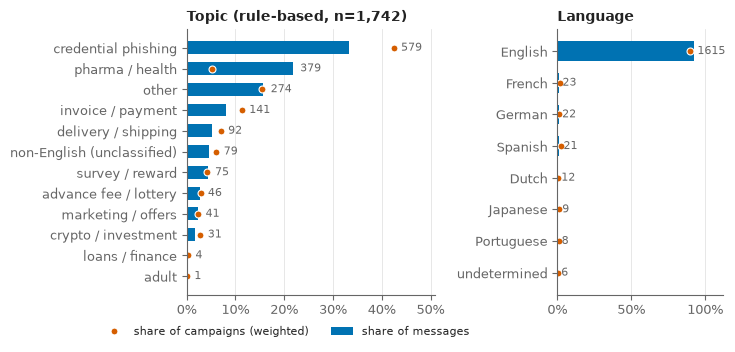

In [14]:
# Figure A: topics (left) and languages (right) over all messages.
# Two bars per row: blue = share of messages, orange = share of campaigns (weighted); each bar is labelled with its percentage and the message count is in brackets.
fig, (ax_topic, ax_language) = plt.subplots(1, 2, figsize=(7.4, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})


def percent(value):
    return f"{value:.0%}" if value >= 0.01 else f"{value:.1%}"      # 0.4% instead of 0%


def grouped_bars(ax, labels, share, weighted, counts, x_max):
    """One pair of horizontal bars per label: message share on top, campaign-weighted share underneath.
    Each bar ends in its percentage; the message count is in the row label."""
    rows, height = np.arange(len(labels)), 0.38
    ax.barh(rows + height / 2, share, height=height, color=BLUE, label="share of messages")
    ax.barh(rows - height / 2, weighted, height=height, color=VERMILION, label="share of campaigns (weighted)")
    ax.set_yticks(rows, [f"{label} ({count})" for label, count in zip(labels, counts)])
    for row, (a, b) in enumerate(zip(share, weighted)):
        ax.text(a + x_max * 0.01, row + height / 2, percent(a), va="center", color=BLUE, fontsize=7.5)
        ax.text(b + x_max * 0.01, row - height / 2, percent(b), va="center", color=VERMILION, fontsize=7.5)
    ax.set_xlim(0, x_max)
    ax.xaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
    ax.grid(axis="x", color=GRID, lw=0.5)
    ax.set_axisbelow(True)


topic_rows = topics[topics.corpus == "all"].sort_values("share")
grouped_bars(ax_topic, topic_rows.value, topic_rows.share, topic_rows.campaign_weighted, topic_rows.n,
             max(topic_rows.share.max(), topic_rows.campaign_weighted.max()) * 1.25)
ax_topic.set_title(f"Topic (rule-based, n={n_all:,})", loc="left", fontweight="bold", fontsize=10)
ax_topic.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.4, -0.08), ncol=2, fontsize=8)

language_rows = languages[languages.corpus == "all"].sort_values("share", ascending=False).head(8).sort_values("share")
grouped_bars(ax_language, [LANGUAGE_NAME.get(code, code) for code in language_rows.value], language_rows.share,
             language_rows.campaign_weighted, language_rows.n, 1.2)
ax_language.set_title("Language", loc="left", fontweight="bold", fontsize=10)
save(fig, "char_topic_language.png")

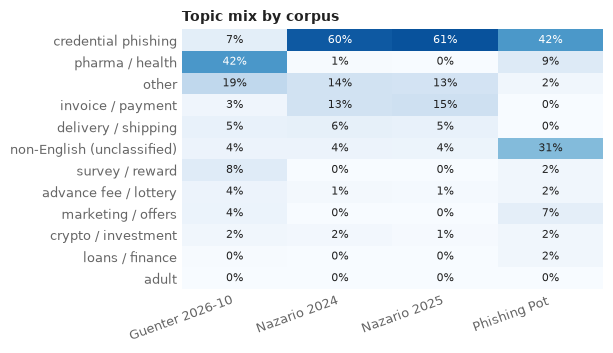

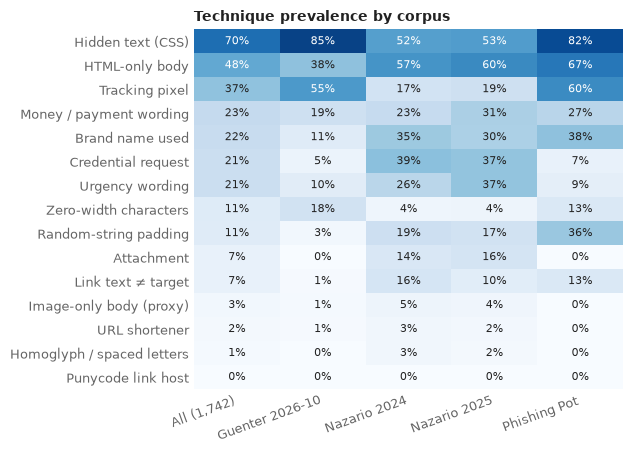

In [15]:
# Figure B: which topics appear in which spam source? (each column adds up to 100%)
topic_order = list(topics[topics.corpus == "all"].sort_values("share", ascending=False).value)
topic_by_corpus = topics[topics.corpus != "all"].pivot(index="value", columns="corpus", values="share").reindex(topic_order).fillna(0)
fig, ax = plt.subplots(figsize=(6.2, 3.6))
draw_heatmap(ax, topic_by_corpus.values, topic_order, [CORPUS_NAME[c] for c in topic_by_corpus.columns])
ax.set_title("Topic mix by corpus", loc="left", fontweight="bold", fontsize=10)
save(fig, "char_topic_by_corpus.png")

# Figure C: how common is each technique, overall and in each spam source?
technique_by_corpus = techniques_table.pivot(index="technique", columns="corpus", values="share")
technique_by_corpus = technique_by_corpus[["all"] + list(CORPUS_NAME)].sort_values("all", ascending=False)
fig, ax = plt.subplots(figsize=(6.4, 4.6))
draw_heatmap(ax, technique_by_corpus.values, [TECHNIQUE_NAME[t] for t in technique_by_corpus.index],
             ["All (1,742)"] + [CORPUS_NAME[c] for c in CORPUS_NAME], vmax=0.8)
ax.set_title("Technique prevalence by corpus", loc="left", fontweight="bold", fontsize=10)
save(fig, "char_techniques.png")